# HR diagrams of the WR population (binaries only)

To show if the "right" systems are selected.

## imports

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation
from helper_functions import tout_L_ZAMS, tout_R_ZAMS



tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

COLORS = {0.0001: '#1f4e79',
           0.001: '#2e75b6',
            0.01: '#5ba3d0', 
             0.1: '#f4a261',
             0.2: '#e76f51',
            0.45: '#c0392b', 
             1.0: '#8e1a0e',
             2.0: '#5c0a0a'
             }

## load POSYDON data

In [2]:
def load_metallicity(metallicity, data_folder):
    """Load and process WR phase data for a single metallicity.

    Returns a dict of arrays ready for analysis.
    """
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
    s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

    s1_Teff = 10**calc_Teff(s1['S1_log_L'], s1['S1_log_R'])
    s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                              s1['S1_mass'].values,
                                              s1['S2_mass'].values)
    s2_Teff = 10**calc_Teff(s2['S2_log_L'], s2['S2_log_R'])
    s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                              s2['S2_mass'].values,
                                              s2['S1_mass'].values)

    return {
        'time':             np.concatenate([s1['time'].values,               s2['time'].values]),
        'weight':           np.concatenate([s1['weight'].values,             s2['weight'].values]),
        'state':            np.concatenate([s1['state'].values,              s2['state'].values]),
        'key':              np.concatenate([s1.index.get_level_values(0),    s2.index.get_level_values(0)]),
        'star':             np.array(['S1'] * len(s1) + ['S2'] * len(s2)),
        'period':           np.concatenate([s1['orbital_period'].values,     s2['orbital_period'].values]),
        'separation':       np.concatenate([s1_sep,                          s2_sep]),
        'Teff':             np.concatenate([s1_Teff.values,                  s2_Teff.values]),
        'L':                np.concatenate([10**s1['S1_log_L'].values,       10**s2['S2_log_L'].values]),
        'optical_depth':    np.concatenate([s1['optical_depth'].values,      s2['optical_depth'].values]),
        'surface_H':        np.concatenate([s1['S1_surface_h1'].values,      s2['S2_surface_h1'].values]),
        'surface_He':       np.concatenate([s1['S1_surface_he4'].values,     s2['S2_surface_he4'].values]),
        'mass':             np.concatenate([s1['S1_mass'].values,            s2['S2_mass'].values]),
        'mass_companion':   np.concatenate([s1['S2_mass'].values,            s2['S1_mass'].values]),
        'radius':           np.concatenate([10**s1['S1_log_R'].values,       10**s2['S2_log_R'].values]),
        'Mdot':             np.concatenate([10**s1['S1_lg_mdot'].values,     10**s2['S2_lg_mdot'].values]),
        'companion':        np.concatenate([s1['S2_state'].values,           s2['S1_state'].values]),
        'S1_state':         np.concatenate([s1['S1_state'].values,           s2['S2_state'].values]),
        'model_weight':     np.concatenate([s1['model_weight'].values,       s2['model_weight'].values]),
    }


data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth_test/')
metallicities = [0.2, 0.45, 1.0]#[0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

In [3]:

def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC


def make_binary_mask(d):
    """Return mask for detached/RLO/contact binaries."""
    s = d['state']
    return (s == 'detached') | (s == 'RLO1') | (s == 'contact') | (s == 'RLO2')

In [4]:
cm_grays = Colormap('colorbrewer:Greys')


In [5]:
LMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/LMC_WRs.csv", sep=",")

# Drop specific BAT99 values
bat99_to_drop = [6, 12, 27, 33, 42, 59, 68, 77, 80, 92, 93, 97, 98, 99, 102, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 116, 117, 118, 119, 126]
LMC_observations = LMC_observations[~LMC_observations['BAT99'].isin(bat99_to_drop)]
obs_single = ~(LMC_observations['Binary?'] != '-')
binary_P_mask = ~obs_single & (LMC_observations['P [d]'] != '-')

In [6]:

SMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/SMC_WRs.data", sep=",")

In [7]:
import json

with open('/Users/max/Documents/projects/WR_population/data/observations/Galactic_WRs.json', 'r') as f:
    observational_data = json.load(f)


obs_df = pd.DataFrame.from_dict(observational_data, orient='index')
obs_df.index.name = 'WR_name'

# Unpack [lower, value, upper] list columns into separate _err_lo, _val, _err_hi columns
list_cols = ['Period', 'Eccentricity', 'M1', 'M2', 'Mass Function', 'M1_sin3i', 'M2_sin3i', 'RA', 'Dec']
for col in list_cols:
    if col in obs_df.columns:
        unpacked = pd.DataFrame(obs_df[col].tolist(), index=obs_df.index,
                                columns=[f'{col}_err_lo', col, f'{col}_err_hi'])
        obs_df = obs_df.drop(columns=col).join(unpacked)


# WR 9 -> Nugis & Lammers (2000)
# L=5.66Lsun; 	T_evol = 139700 (unsure if I trust this)

# WR 11
# L=110,000±40,000Lsun T = 57,100±1,700 K

In [16]:
obs_df

,System Name,evol_type_1,evol_type_2,obs_type_1,obs_type_2,system_class,Detection Method,Reference,Notes,Period_err_lo,...,M1_sin3i_err_hi,M2_sin3i_err_lo,M2_sin3i,M2_sin3i_err_hi,RA_err_lo,RA,RA_err_hi,Dec_err_lo,Dec,Dec_err_hi
WR_name,,,,,,,,,,,,,,,,,,,,,
WR 9,[WR 9],He-star,MS,WC5,O7,WR binary,"[RV, SB2]","[1995IAUS..163..223N, 2001NewAR..45..135V]",None,NaN,...,NaN,NaN,18.80,NaN,2.722222e-09,116.459997,2.722222e-09,3.166667e-09,-34.330139,3.166667e-09
WR 11,[WR 11],He-star,MS,WC8,O7.5III-V,WR binary,"[RV, SB2]","[2001NewAR..45..135V, 2007MNRAS.377..415N]",None,0.010000,...,0.60,1.10,21.60,1.10,NaN,122.383126,NaN,NaN,-47.336586,NaN
WR 19,[WR 19],He-star,MS,WC4pd,O9.5-9.7,WR binary,[CWB],"[2001NewAR..45..135V, 2009MNRAS.395.2221W]",dust-producing CWB; orbit measured for O9 star...,37.000000,...,2.00,NaN,NaN,NaN,3.166667e-09,154.520786,3.166667e-09,3.083333e-09,-58.273957,3.083333e-09
WR 21,[WR 21],He-star,MS,WN5,O4-6,WR binary,"[RV, SB2]","[1999IAUS..193...26N, 2001NewAR..45..135V]",errors not provided by Niemela+1999 or VdH21,0.000100,...,NaN,NaN,16.30,NaN,3.694444e-09,156.485427,3.694444e-09,3.472222e-09,-57.812089,3.472222e-09
WR 29,[WR 29],He-star,MS,WN7h,O,WR binary,"[RV, SB2]","[2001NewAR..45..135V, 2009A&A...506.1269G]",None,0.000010,...,2.00,1.00,16.00,1.00,5.000000e-07,10.391684,5.000000e-07,5.000000e-07,-61.120781,5.000000e-07
WR 30,[WR 30],He-star,MS,WC6,O6-8,WR binary,"[RV, SB2]",[2001NewAR..45..135V],None,NaN,...,NaN,NaN,31.90,NaN,NaN,162.774958,NaN,NaN,-62.283778,NaN
WR 30a,[WR 30a],He-star,MS,WO4,O5-5.5,WR binary,"[RV, SB2]","[1995IAUS..163..223N, 2001NewAR..45..135V]",None,NaN,...,NaN,NaN,NaN,NaN,2.361111e-09,162.912110,2.361111e-09,2.361111e-09,-60.943030,2.361111e-09
WR 31,[WR 31],He-star,MS,WN4,O8V,WR binary,"[RV, SB2]","[2001NewAR..45..135V, 2012MNRAS.424.1601F]",Minimum masses computed using values from Fahe...,0.000013,...,0.18,0.37,6.48,0.37,5.111111e-09,165.072509,5.111111e-09,5.361111e-09,-51.492782,5.361111e-09
WR 35a,[WR 35a],He-star,MS,WN6,O8.5V,WR binary,"[RV, SB2]","[2001NewAR..45..135V, 2014A&A...562A..13G]","Assuming a 5km/s error on K2, taking the solut...",0.009000,...,2.40,3.90,23.00,3.90,NaN,165.101407,NaN,NaN,-59.993235,NaN


54 23


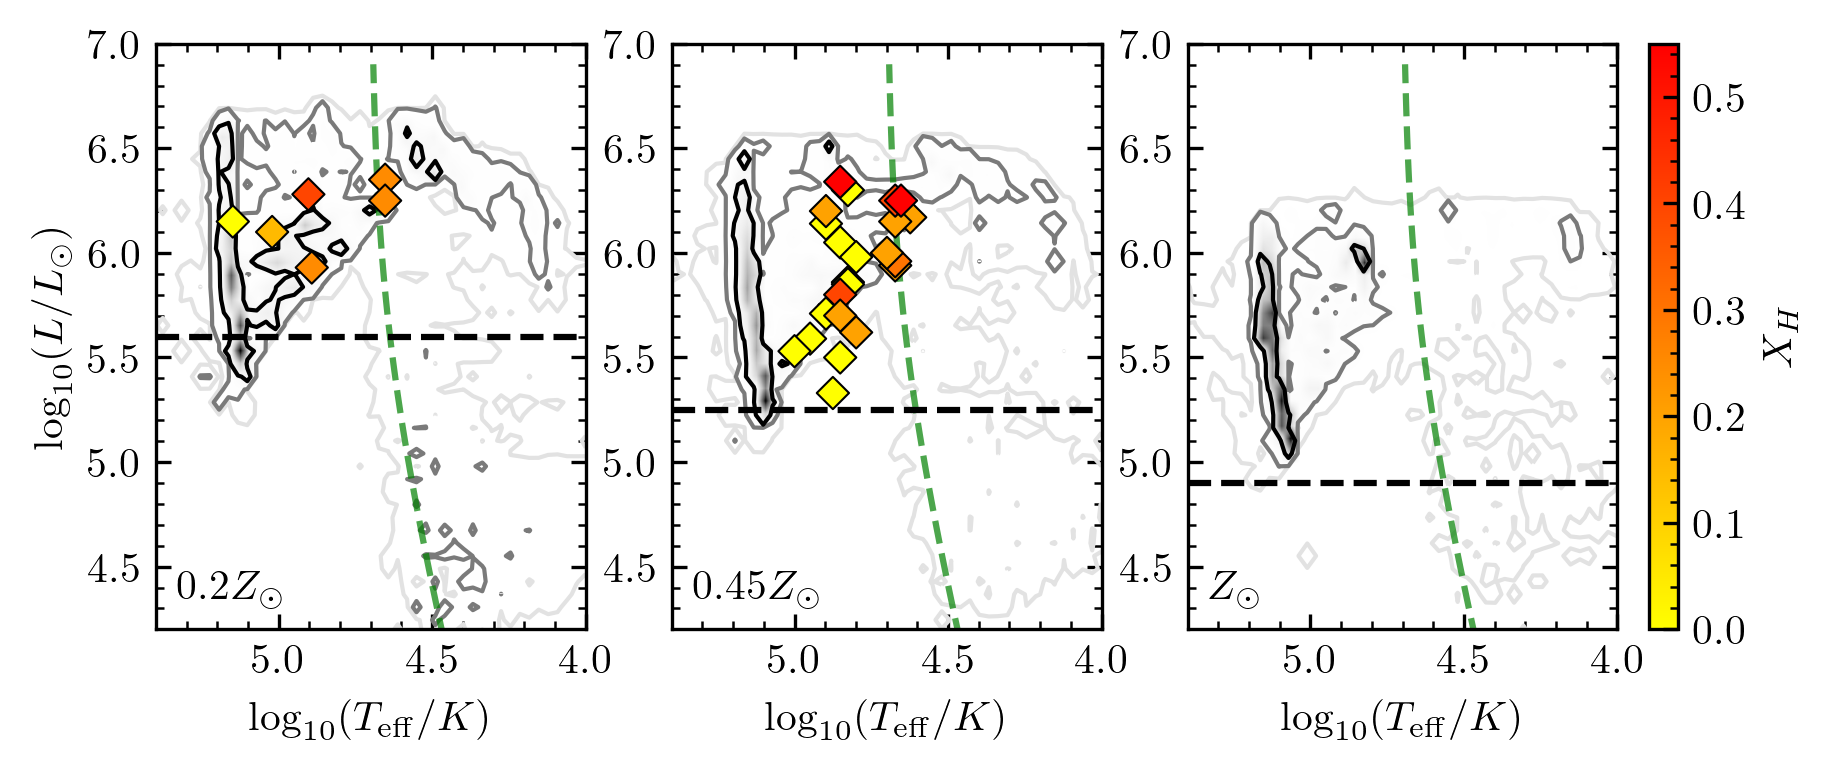

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535))


for i, met in enumerate(metallicities):
    Teff_array = WR_data[met]['Teff']
    L_array = WR_data[met]['L']
    weight_array = WR_data[met]['weight'] * WR_data[met]['model_weight']

    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    WR_mask = WNL | WNE | WC
    T_bins = np.linspace(4.0, 5.5, 51)
    L_bins = np.linspace(4.0, 7.0, 51)

    (H0, xedges, yedges) = \
            np.histogram2d(np.log10(Teff_array)[mask & WR_mask],
                        np.log10(L_array)[mask & WR_mask],
                        weights=weight_array[mask & WR_mask],
                        bins=[T_bins, L_bins])
            
            
    H0 /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
    H0_sorted = np.sort(H0.flatten())[::-1]
    H0_cumsum = H0_sorted.cumsum()
    H0_total = H0_cumsum[-1]
    # Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
    level0_1 = H0_sorted[np.searchsorted(H0_cumsum, 0.683 * H0_total)]
    level0_2 = H0_sorted[np.searchsorted(H0_cumsum, 0.954 * H0_total)]
    level0_3 = H0_sorted[np.searchsorted(H0_cumsum, 0.997 * H0_total)]
    levels0 = [level0_3, level0_2, level0_1]

    axes[i].imshow(H0.T,
                origin='lower',
                extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
                cmap=cm_grays.to_mpl(),
                aspect='auto',
                interpolation='bilinear')

    axes[i].contour(H0.T,
                     levels=levels0,
                     colors=cm_grays([0.2, 0.6, 1.0]),
                     linewidths=[1.0, 1.0, 1.0],
                extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])


for ax in axes:
    ax.set_xlim(5.4, 4.0)
    ax.set_ylim(4.2, 7.0)

    ax.set_xlabel('$\log_{10}(T_\mathrm{eff}/K)$')

axes[0].set_ylabel('$\log_{10}(L/L_\odot)$')


# Add ZAMS and HeMS lines
# ZAMS from Hurley et al. (2000, MNRAS, 315, 543)
# Using their fitting formulas for solar metallicity
# For M in range ~1-120 Msun, compute ZAMS L and Teff
M_zams = np.logspace(0.7, 2.5, 100) 

L_zams = tout_L_ZAMS(M_zams)
R_zams = tout_R_ZAMS(M_zams)

# Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
# log(Teff) approximation for MS stars
log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
log_L_zams = np.log10(L_zams)
for ax in axes:
    ax.plot(log_Teff_zams, log_L_zams, 'g--', linewidth=1.5, label='ZAMS', alpha=0.7)
    #ax.plot([], [], 'b--', linewidth=1.5, label='$1\sigma$ WN contour', alpha=0.7)
    #ax.plot([], [], 'r--', linewidth=1.5, label='$1\sigma$ WC contour', alpha=0.7)
    
    
axes[0].axhline(5.6, color='k', linestyle='--', linewidth=1.5, label='$\log_{10}(L/L_\odot) = 5.25$')
axes[1].axhline(5.25, color='k', linestyle='--', linewidth=1.5, label='$\log_{10}(L/L_\odot) = 5.25$')
axes[2].axhline(4.9, color='k', linestyle='--', linewidth=1.5, label='$\log_{10}(L/L_\odot) = 4.9$')

# Scatter plot colored by X_H
# single
tol_nightfall = Colormap('matlab:autumn_r')

obs_single = ~(LMC_observations['Binary?'] != '-')
print(np.sum(obs_single), np.sum(~obs_single))
# scatter = axes[1].scatter(np.log10(LMC_observations['T_eff[kK]']*1e3)[obs_single], 
#                       LMC_observations['log(L) [Lsun]'][obs_single], 
#                       c=LMC_observations['X_H'][obs_single], 
#                       cmap=tol_nightfall.to_mpl(),
#                       zorder=5,
#                       edgecolors='black',
#                       linewidths=0.5,
#                       vmin=0.0,
#                       vmax=0.55,
#                       s=30)

scatter = axes[1].scatter(np.log10(LMC_observations['T_eff[kK]']*1e3)[~obs_single], 
                      LMC_observations['log(L) [Lsun]'][~obs_single], 
                      c=LMC_observations['X_H'][~obs_single], 
                      cmap=tol_nightfall.to_mpl(),
                      label='Obs.', 
                      zorder=5,
                      marker='D',
                      edgecolors='black',
                      linewidths=0.5,
                      vmin=0.0,
                      vmax=0.55,
                      s=30)


binary_mask = SMC_observations['binary_type'].str.contains('binary')
#SMC_observations[binary_mask]


scatter = axes[0].scatter(np.log10(SMC_observations['T_eff[kK]']*1e3)[binary_mask], 
                      SMC_observations['log_L'][binary_mask], 
                      c=SMC_observations['X_H'][binary_mask], 
                      cmap=tol_nightfall.to_mpl(),
                      label='Obs.', 
                      zorder=5,
                      marker='D',
                      edgecolors='black',
                      linewidths=0.5,
                      vmin=0.0,
                      vmax=0.55,
                      s=30)


# scatter = axes[2].scatter(np.log10(obs_df['Teff'][obs_df['Binary?'] == 'Yes']), 
#                       obs_df['log_L'][obs_df['Binary?'] == 'No'], 
#                       c=obs_df['X_H'][obs_df['Binary?'] == 'No'], 
#                       cmap=tol_nightfall.to_mpl(),
#                       label='Obs.', 
#                       zorder=5,
#                       marker='D',
#                       edgecolors='black',
#                       linewidths=0.5,
#                       vmin=0.0,
#                       vmax=0.55,
#                       s=30)

plt.colorbar(scatter, ax=axes, label='$X_H$', orientation='vertical', pad=0.02, fraction=0.05)

axes[0].text(0.05, 0.1, '$0.2 Z_\odot$', transform=axes[0].transAxes, verticalalignment='top')
axes[1].text(0.05, 0.1, '$0.45 Z_\odot$', transform=axes[1].transAxes, verticalalignment='top')
axes[2].text(0.05, 0.1, '$Z_\odot$', transform=axes[2].transAxes, verticalalignment='top')
    


figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'
plt.savefig(figure_paths + 'pdf/HR_diagrams.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/HR_diagrams.png', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
SMC_observations
#print(10)

In [22]:
import json

with open('/Users/max/Documents/projects/WR_population/data/observations/Galactic_WRs.json', 'r') as f:
    observational_data = json.load(f)


obs_df = pd.DataFrame.from_dict(observational_data, orient='index')
obs_df.index.name = 'WR_name'

# Unpack [lower, value, upper] list columns into separate _err_lo, _val, _err_hi columns
list_cols = ['Period', 'Eccentricity', 'M1', 'M2', 'Mass Function', 'M1_sin3i', 'M2_sin3i', 'RA', 'Dec']
for col in list_cols:
    if col in obs_df.columns:
        unpacked = pd.DataFrame(obs_df[col].tolist(), index=obs_df.index,
                                columns=[f'{col}_err_lo', col, f'{col}_err_hi'])
        obs_df = obs_df.drop(columns=col).join(unpacked)



In [26]:
obs_df.columns

Index(['System Name', 'evol_type_1', 'evol_type_2', 'obs_type_1', 'obs_type_2',
       'system_class', 'Detection Method', 'Reference', 'Notes',
       'Period_err_lo', 'Period', 'Period_err_hi', 'Eccentricity_err_lo',
       'Eccentricity', 'Eccentricity_err_hi', 'M1_err_lo', 'M1', 'M1_err_hi',
       'M2_err_lo', 'M2', 'M2_err_hi', 'Mass Function_err_lo', 'Mass Function',
       'Mass Function_err_hi', 'M1_sin3i_err_lo', 'M1_sin3i',
       'M1_sin3i_err_hi', 'M2_sin3i_err_lo', 'M2_sin3i', 'M2_sin3i_err_hi',
       'RA_err_lo', 'RA', 'RA_err_hi', 'Dec_err_lo', 'Dec', 'Dec_err_hi'],
      dtype='object')

In [28]:
obs_df['M1']

WR_name
WR 9        9.00
WR 11       9.00
WR 19        NaN
WR 21      19.00
WR 29        NaN
WR 30      16.00
WR 30a      2.90
WR 31        NaN
WR 35a       NaN
WR 42      14.00
WR 47      41.80
WR 48        NaN
WR 62a       NaN
WR 68a       NaN
WR 79       5.00
WR 97        NaN
WR 104       NaN
WR 113     20.30
WR 125       NaN
WR 127     21.20
WR 133     10.20
WR 137      9.50
WR 139     10.70
WR 140     10.31
WR 145a      NaN
WR 151     20.40
WR 155     24.50
Name: M1, dtype: float64